# Sales Prediction Using Python

## 1. Project Overview
Sales Prediction is a Data Science and Machine Learning
project that aims to predict product sales using historical
sales and related information.

## 2. Project Objective
The main objective is to analyse sales data and develop
a Machine Learning model that can predict future sales.

## 3. Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Project Workflow
1. Load the dataset.
2. Explore and understand the data.
3. Clean the dataset.
4. Perform data analysis.
5. Create visualizations.
6. Prepare training and testing data.
7. Train a Machine Learning model.
8. Predict sales.
9. Evaluate model performance.

In [137]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [138]:
# Load the Advertising dataset

df = pd.read_csv("Advertising.csv")

print("Sales Dataset Loaded Successfully!")

# Display the first five rows
display(df.head())

# Check dataset size
print("Dataset Shape:", df.shape)

Sales Dataset Loaded Successfully!


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


Dataset Shape: (200, 4)


In [139]:
# Check dataset information

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [140]:
# Statistical analysis of sales dataset

print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


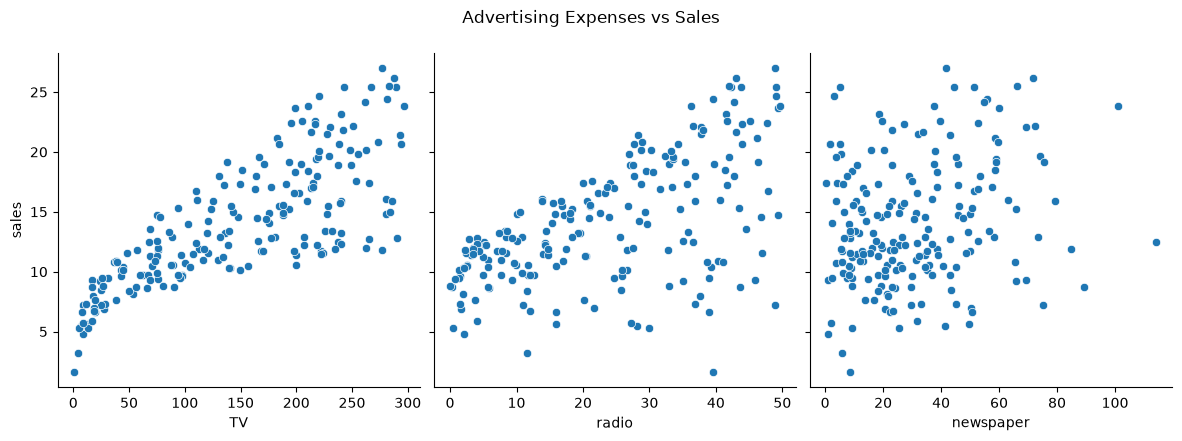

In [141]:
# Visualize the relationship between advertising and sales

sns.pairplot(
    df,
    x_vars=["TV", "radio", "newspaper"],
    y_vars=["sales"],
    height=4,
    aspect=1
)

plt.suptitle(
    "Advertising Expenses vs Sales",
    y=1.08
)

plt.show()

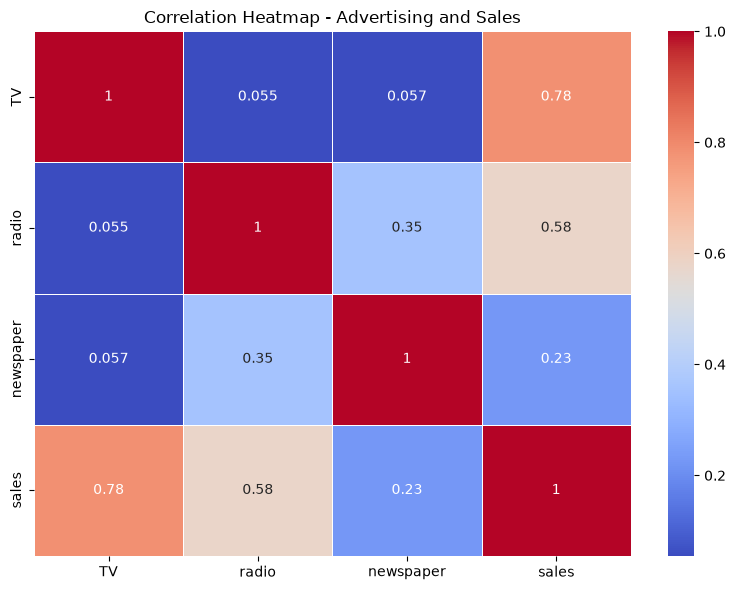

In [142]:
# Create correlation heatmap

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Advertising and Sales")
plt.tight_layout()
plt.show()

In [143]:
# Separate features and target

X = df[["TV", "radio", "newspaper"]]

y = df["sales"]

print("Features and Target Separated Successfully!")

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features and Target Separated Successfully!
Features Shape: (200, 3)
Target Shape: (200,)


,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [144]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dataset Split Successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Dataset Split Successfully!
Training Features: (160, 3)
Testing Features: (40, 3)
Training Target: (160,)
Testing Target: (40,)


In [145]:
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [146]:
# Predict sales using the trained model

y_pred = model.predict(X_test)

print("Sales Prediction Completed Successfully!")

# Compare actual sales with predicted sales
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

print("\nActual vs Predicted Sales:")
display(comparison.head(10))

Sales Prediction Completed Successfully!

Actual vs Predicted Sales:


,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


In [147]:
# Evaluate the Linear Regression Model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

MODEL PERFORMANCE
Mean Absolute Error: 1.4607567168117603
Mean Squared Error: 3.1740973539761033
Root Mean Squared Error: 1.78159966153345
R2 Score: 0.899438024100912


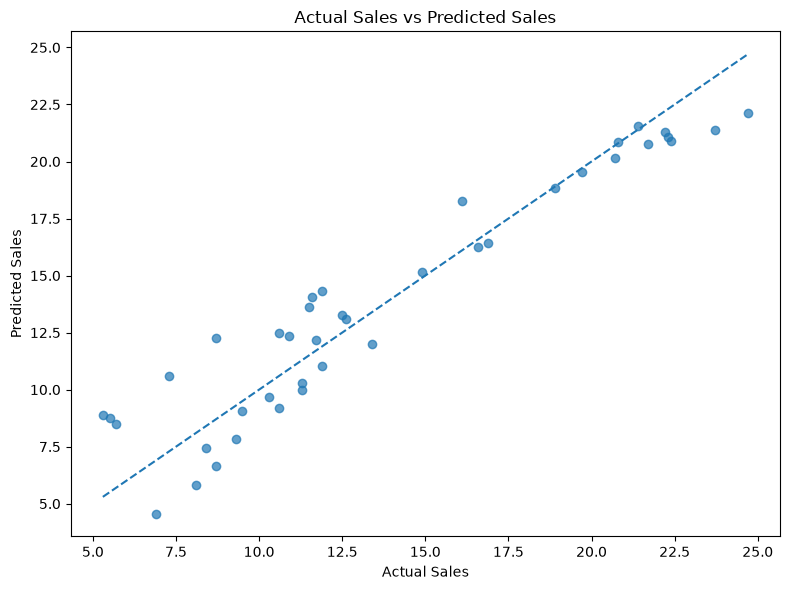

In [148]:
# Compare Actual Sales with Predicted Sales

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Draw reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual Sales vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.tight_layout()
plt.show()

Residual Analysis:
Average Residual: -0.09752119905509948


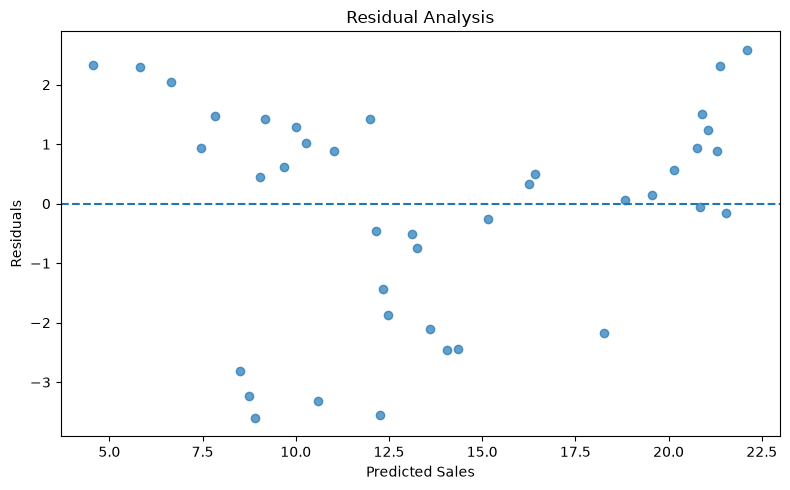

In [149]:
# Calculate prediction errors (residuals)

residuals = y_test - y_pred

print("Residual Analysis:")
print("Average Residual:", residuals.mean())

# Visualize residuals
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Analysis")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()

In [150]:
# Predict sales for new advertising budgets

new_data = pd.DataFrame({
    "TV": [100],
    "radio": [25],
    "newspaper": [20]
})

# Make prediction
new_prediction = model.predict(new_data)

print("New Advertising Budgets:")
display(new_data)

print("Predicted Sales:", new_prediction[0])

New Advertising Budgets:


,TV,radio,newspaper
0,100,25,20


Predicted Sales: 12.237117727681019


Advertising Coefficients:


,Advertising Platform,Coefficient
0,TV,0.044730
1,radio,0.189195
2,newspaper,0.002761


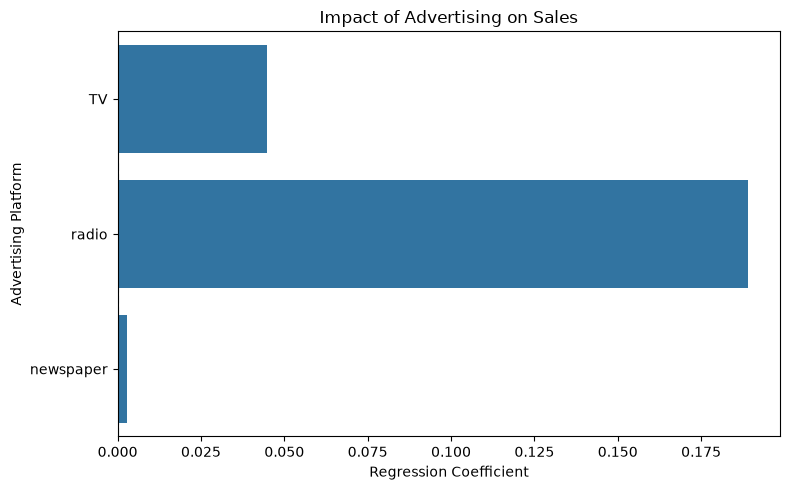

In [151]:
# Analyse the effect of advertising platforms on sales

coefficients = pd.DataFrame({
    "Advertising Platform": X.columns,
    "Coefficient": model.coef_
})

print("Advertising Coefficients:")
display(coefficients)

# Visualize the coefficients
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Advertising Platform"
)

plt.axvline(x=0, linestyle="--")
plt.title("Impact of Advertising on Sales")
plt.xlabel("Regression Coefficient")
plt.ylabel("Advertising Platform")

plt.tight_layout()
plt.show()

In [152]:
# Final Model Performance Summary

final_results = pd.DataFrame({
    "Evaluation Metric": [
        "Mean Absolute Error",
        "Mean Squared Error",
        "Root Mean Squared Error",
        "R2 Score"
    ],
    "Result": [
        round(mae, 3),
        round(mse, 3),
        round(rmse, 3),
        round(r2, 3)
    ]
})

print("FINAL SALES PREDICTION MODEL RESULTS")
display(final_results)

print("New Sales Prediction:", round(new_prediction[0], 2))

FINAL SALES PREDICTION MODEL RESULTS


,Evaluation Metric,Result
0,Mean Absolute Error,1.461
1,Mean Squared Error,3.174
2,Root Mean Squared Error,1.782
3,R2 Score,0.899


New Sales Prediction: 12.24


## Model Performance

- Algorithm: Linear Regression
- Training Data: 80%
- Testing Data: 20%
- Mean Absolute Error: 1.461
- Mean Squared Error: 3.174
- Root Mean Squared Error: 1.782
- R2 Score: 0.899
- New Sales Prediction: 12.24

The model achieved an R2 score of 0.899,
showing a good relationship between the
advertising expenditure and predicted sales.

# Conclusion

The Sales Prediction project was successfully implemented
using Python and Machine Learning.

In this project, we used the Advertising dataset containing
200 records and four columns: TV, Radio, Newspaper and Sales.

We performed data analysis, checked missing values,
created visualizations and studied the relationship
between advertising expenditure and sales.

We used the Linear Regression algorithm to train our
Machine Learning model.

The model achieved an R2 score of 0.899, showing that
it explains 89.9% of the variation in sales on the test data.

We also tested the model using new advertising budgets
and obtained a predicted sales value of 12.24.

## Final Outcome

- Dataset: Advertising.csv
- Total Records: 200
- Algorithm: Linear Regression
- Training Data: 80%
- Testing Data: 20%
- R2 Score: 0.899
- Predicted Sales: 12.24

This project helped us understand data analysis,
data visualization, regression, model training and
sales prediction.